# Exercises XP — Matplotlib and Seaborn

Octopus Week 2 · Day 4

[Assignment](https://octopus.developers.institute/courses/collection/254/course/812/section/1705/chapter/4336)

Run cells in order. Source datasets are in `../data`; see the root README for setup and provenance.

In [1]:
from pathlib import Path
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / 'analysis_utils.py').exists())
sys.path.insert(0, str(ROOT))
sns.set_theme(style='whitegrid')
def load(kind, filename=None, **kwargs):
    files = list((ROOT / 'data' / kind).rglob(filename or '*.csv'))
    if len(files) != 1:
        raise ValueError(f'Select an unambiguous data file: {files}')
    return pd.read_csv(files[0], **kwargs)
def savefig(name):
    target = ROOT / 'figures'
    target.mkdir(exist_ok=True)
    plt.tight_layout()
    plt.savefig(target / (name + '.png'), dpi=140, bbox_inches='tight')
    plt.show()


## Exercise 1 — Why visualize?
Visualization makes comparisons, distributions, unusual values and trends easier to inspect than a table alone. Axis choices, denominators and uncertainty affect interpretation, so charts need clear labels and context. A line graph shows change along an ordered coordinate such as time; joining points implies continuity and is unsuitable for unrelated categories.

## Exercise 2 — Weekly temperature line plot

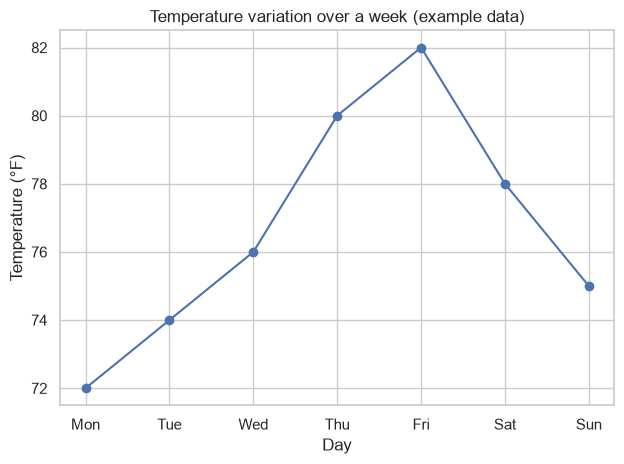

In [2]:
days=['Mon','Tue','Wed','Thu','Fri','Sat','Sun'];temperatures=[72,74,76,80,82,78,75]
plt.plot(days,temperatures,marker='o');plt.xlabel('Day');plt.ylabel('Temperature (°F)');plt.title('Temperature variation over a week (example data)')
savefig('day4_temperature')

## Exercise 3 — Monthly sales bar chart

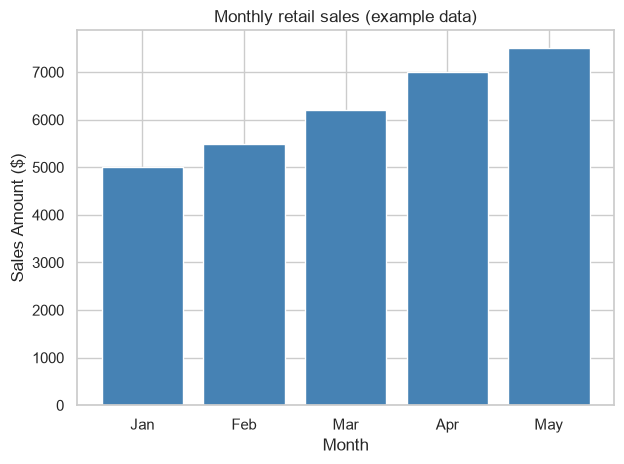

In [3]:
months=['Jan','Feb','Mar','Apr','May'];sales=[5000,5500,6200,7000,7500]
plt.bar(months,sales,color='steelblue');plt.xlabel('Month');plt.ylabel('Sales Amount ($)');plt.title('Monthly retail sales (example data)')
savefig('day4_monthly_sales_example')

## Load Student Mental Health
Use the real supplied file (101 respondents). The file spells the panic column “Do you have Panic attack?”; use that observed name. Strip category whitespace. Retain missing ages as missing and omit them only from the age scatter, reporting the count. This convenience sample and self-reported outcomes do not establish clinical diagnoses or representative population differences.

In [4]:
df=load('student')
for c in df.select_dtypes(include=['str','object']).columns:
    df[c]=df[c].str.strip()
display(df.head());display(df.isna().sum().to_frame('missing'))

,Timestamp,Choose your gender,Age,What is your course?,Your current year of Study,What is your CGPA?,Marital status,Do you have Depression?,Do you have Anxiety?,Do you have Panic attack?,Did you seek any specialist for a treatment?
0,8/7/2020 12:02,Female,18.0,Engineering,year 1,3.00 - 3.49,No,Yes,No,Yes,No
1,8/7/2020 12:04,Male,21.0,Islamic education,year 2,3.00 - 3.49,No,No,Yes,No,No
2,8/7/2020 12:05,Male,19.0,BIT,Year 1,3.00 - 3.49,No,Yes,Yes,Yes,No
3,8/7/2020 12:06,Female,22.0,Laws,year 3,3.00 - 3.49,Yes,Yes,No,No,No
4,8/7/2020 12:13,Male,23.0,Mathemathics,year 4,3.00 - 3.49,No,No,No,No,No


,missing
Timestamp,0
Choose your gender,0
Age,1
What is your course?,0
Your current year of Study,0
What is your CGPA?,0
Marital status,0
Do you have Depression?,0
Do you have Anxiety?,0
Do you have Panic attack?,0


## Exercise 4 — CGPA category histogram
CGPA is supplied as intervals, not exact grades. Count the ordered intervals without inventing point values.

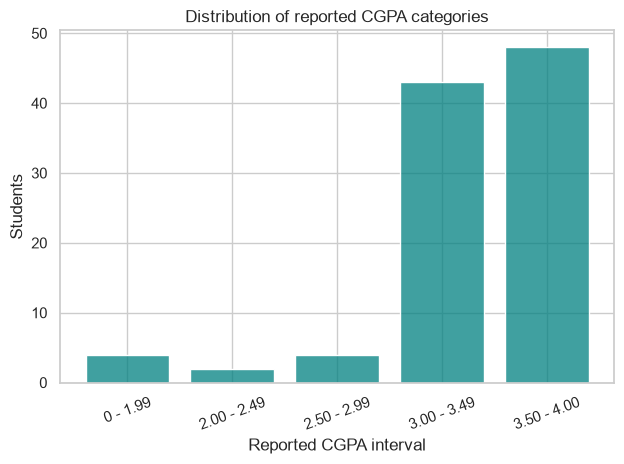

In [5]:
order=sorted(df['What is your CGPA?'].dropna().unique())
df['CGPA category']=pd.Categorical(df['What is your CGPA?'],categories=order,ordered=True)
sns.histplot(data=df,x='CGPA category',discrete=True,color='teal',shrink=.8)
plt.xlabel('Reported CGPA interval');plt.ylabel('Students');plt.title('Distribution of reported CGPA categories');plt.xticks(rotation=20)
savefig('day4_cgpa')

## Exercise 5 — Anxiety proportions across genders
Map Yes/No to 1/0, then the bar height is the within-gender proportion, rather than a raw count. Show group sizes and avoid interpreting sample differences as causal.

,count,mean
Choose your gender,,
Female,75,0.320000
Male,26,0.384615


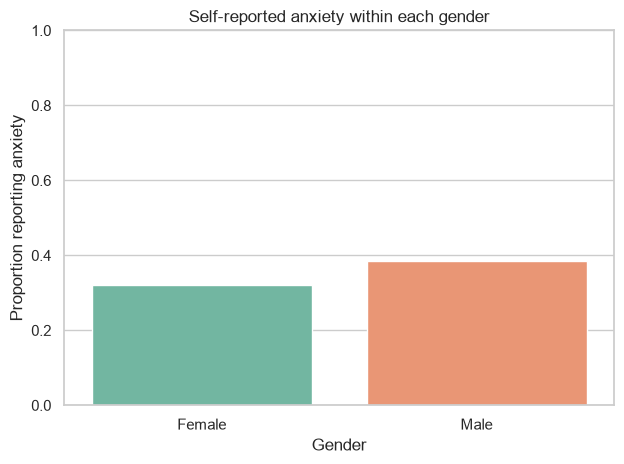

In [6]:
df['Anxiety']=df['Do you have Anxiety?'].map({'Yes':1,'No':0})
display(df.groupby('Choose your gender')['Anxiety'].agg(['count','mean']))
sns.barplot(data=df,x='Choose your gender',y='Anxiety',hue='Choose your gender',palette='Set2',legend=False,errorbar=None)
plt.ylim(0,1);plt.xlabel('Gender');plt.ylabel('Proportion reporting anxiety');plt.title('Self-reported anxiety within each gender')
savefig('day4_anxiety')

## Exercise 6 — Age and panic attacks
Binary outcomes overlap in a scatter plot; use transparency and small markers. Missing ages are omitted, and y ticks retain readable response labels.

Rows excluded for missing age/response: 1


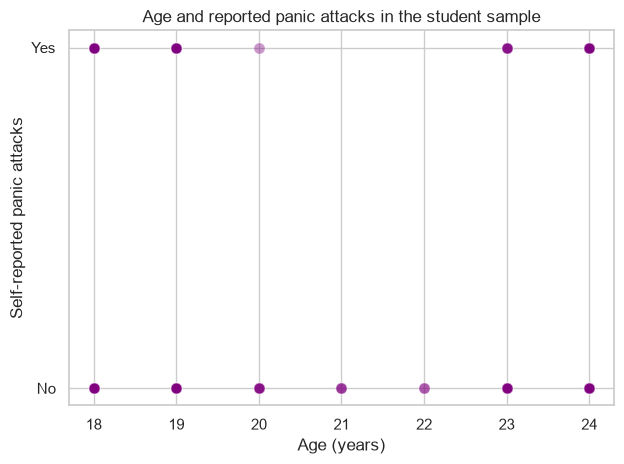

A binary scatter is descriptive; overplotting and this small convenience sample limit inference.


In [7]:
df['Panic']=df['Do you have Panic attack?'].map({'Yes':1,'No':0})
plot_df=df.dropna(subset=['Age','Panic'])
print('Rows excluded for missing age/response:',len(df)-len(plot_df))
sns.scatterplot(data=plot_df,x='Age',y='Panic',alpha=.4,s=65,color='purple')
plt.yticks([0,1],['No','Yes']);plt.xlabel('Age (years)');plt.ylabel('Self-reported panic attacks');plt.title('Age and reported panic attacks in the student sample')
savefig('day4_panic')
print('A binary scatter is descriptive; overplotting and this small convenience sample limit inference.')